# Fetal Head Segmentation — Model Template & Dedicated Experiment Suite

This notebook is based on [`UNet.ipynb`](../UNet.ipynb).  
**Features & Pipeline:**
- Dedicated experiment directory created at `Experiments/<MODEL_NAME>/` for every model run.
- Model definition is a **placeholder** — swap in your own architecture.
- Early stopping monitors **Validation Dice score**.
- Validation includes **HD95** and **ASSD** distance metrics.
- Best model checkpoint, optimizer/scheduler states saved in `<MODEL_NAME>/checkpoints/`.
- CSV logs (`training_metrics.csv`, `validation_metrics.csv`, `test_metrics.csv`, `gradcam_report.csv`) saved in `<MODEL_NAME>/logs/`.
- Grad-CAM visualizations saved in `<MODEL_NAME>/gradcam/`.
- Feature Map & Attention Map visualizers saved in `<MODEL_NAME>/feature_maps/` & `<MODEL_NAME>/attention_maps/`.
- 300 DPI Publication-Ready Figures saved in `<MODEL_NAME>/figures/`.


## 1 · Install Dependencies

In [1]:
!pip install ipywidgets
!pip install metrics
!pip install -q albumentations opencv-python-headless pandas numpy scikit-learn scikit-image \
    matplotlib seaborn tqdm medpy thop
!pip install segmentation_models_pytorch torchsummary 
%pip install torchinfo
%pip install ptflops



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2 · Imports

In [2]:
import os
import cv2
import time
import random
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from torchinfo import summary
from scipy.ndimage import distance_transform_edt, binary_erosion

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline


## 3 · Data & Experiment Directory Configuration

In [3]:
# --- Model Identifier ---
MODEL_NAME = "msunet"  # <-- Change this per model (e.g. 'UNet_VGG16', 'ResAttnUNet', 'SwinUNet')

# --- Dataset Paths ---
DATA_DIR = r'C:\Users\shyle\OneDrive\Documents\Projects\Fetus\HC18'
x_train_dir = os.path.join(DATA_DIR, 'train', 'images')
y_train_dir = os.path.join(DATA_DIR, 'train', 'masks')
x_valid_dir = os.path.join(DATA_DIR, 'val', 'images')
y_valid_dir = os.path.join(DATA_DIR, 'val', 'masks')
x_test_dir  = os.path.join(DATA_DIR, 'test', 'images')
select_class_gray_values = [255]

# --- Dedicated Model Experiment Directory Structure ---
EXPERIMENTS_ROOT = r'C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments'
MODEL_DIR        = os.path.join(EXPERIMENTS_ROOT, MODEL_NAME)
CHECKPOINT_DIR   = os.path.join(MODEL_DIR, 'checkpoints')
LOGS_DIR         = os.path.join(MODEL_DIR, 'logs')
GRADCAM_DIR      = os.path.join(MODEL_DIR, 'gradcam')
FEATUREMAP_DIR   = os.path.join(MODEL_DIR, 'feature_maps')
ATTENTION_DIR    = os.path.join(MODEL_DIR, 'attention_maps')
FIGURES_DIR      = os.path.join(MODEL_DIR, 'figures')

for d in [MODEL_DIR, CHECKPOINT_DIR, LOGS_DIR, GRADCAM_DIR, FEATUREMAP_DIR, ATTENTION_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

best_model_path = os.path.join(CHECKPOINT_DIR, f'best_model_{MODEL_NAME}.pth')
print(f"📁 Dedicated Experiment Directory Created: {MODEL_DIR}")


📁 Dedicated Experiment Directory Created: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet


## 4 · Visualisation Helper

In [4]:
def visualize(**images):
    n = len(images)
    plt.figure(figsize=(5*n, 5))
    for i, (name, image) in enumerate(images.items()):
        plt.subplot(1, n, i + 1)
        plt.title(name)
        plt.imshow(image.squeeze(), cmap='gray')
        plt.axis('off')
    plt.show()


## 5 · Dataset

In [5]:
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset
from glob import glob
import os

def fill_mask_border(mask):
    """Fill the white ellipse border in a binary mask to create a solid region."""
    mask = (mask * 255).astype(np.uint8) if mask.max() <= 1 else mask.copy()
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled_mask = np.zeros_like(mask)
    cv2.drawContours(filled_mask, contours, -1, color=255, thickness=cv2.FILLED)
    return (filled_mask / 255).astype(np.float32)

class FetalHeadDataset(Dataset):
    def __init__(self, images_dir, masks_dir, class_gray_values, augmentation=None, preprocessing=None):
        self.image_paths = sorted(glob(os.path.join(images_dir, '*')))
        self.mask_paths  = sorted(glob(os.path.join(masks_dir, '*'))) if masks_dir and os.path.exists(masks_dir) else []
        self.class_gray_values = class_gray_values
        self.augmentation = augmentation
        self.preprocessing = preprocessing

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, i):
        image = cv2.imread(self.image_paths[i], cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise FileNotFoundError(f"Image not found: {self.image_paths[i]}")

        if i < len(self.mask_paths):
            mask = cv2.imread(self.mask_paths[i], cv2.IMREAD_GRAYSCALE)
            if mask is None:
                mask = np.zeros_like(image, dtype=np.float32)
            else:
                mask = fill_mask_border(mask)
                if self.class_gray_values:
                    mask = np.isin(mask * 255, self.class_gray_values).astype('float32')
                else:
                    mask = mask.astype('float32')
        else:
            mask = np.zeros_like(image, dtype=np.float32)

        image = image.astype('float32') / 255.0
        image = np.expand_dims(image, -1)
        mask  = np.expand_dims(mask, -1)

        if self.augmentation:
            augmented = self.augmentation(image=image, mask=mask)
            image, mask = augmented['image'], augmented['mask']

        if self.preprocessing:
            processed = self.preprocessing(image=image, mask=mask)
            image, mask = processed['image'], processed['mask']

        if isinstance(mask, torch.Tensor):
            if mask.ndim == 4 and mask.shape[-1] == 1:
                mask = mask.squeeze(-1)
            if mask.ndim == 2:
                mask = mask.unsqueeze(0)
            if mask.ndim == 3 and mask.shape[0] != 1 and mask.shape[-1] == 1:
                mask = mask.permute(2, 0, 1)
        elif isinstance(mask, np.ndarray):
            if mask.ndim == 4 and mask.shape[-1] == 1:
                mask = np.squeeze(mask, axis=-1)
            if mask.ndim == 2:
                mask = np.expand_dims(mask, 0)
            if mask.ndim == 3 and mask.shape[0] != 1 and mask.shape[-1] == 1:
                mask = np.transpose(mask, (2, 0, 1))
            mask = torch.from_numpy(mask).float()

        assert mask.shape == (1, 256, 256), f"Mask shape: {mask.shape}"

        if isinstance(image, torch.Tensor):
            if image.ndim == 4 and image.shape[-1] == 1:
                image = image.squeeze(-1)
            if image.ndim == 2:
                image = image.unsqueeze(0)
            if image.ndim == 3 and image.shape[0] != 1 and image.shape[-1] == 1:
                image = image.permute(2, 0, 1)
        elif isinstance(image, np.ndarray):
            if image.ndim == 4 and image.shape[-1] == 1:
                image = np.squeeze(image, axis=-1)
            if image.ndim == 2:
                image = np.expand_dims(image, 0)
            if image.ndim == 3 and image.shape[0] != 1 and image.shape[-1] == 1:
                image = np.transpose(image, (2, 0, 1))
            image = torch.from_numpy(image).float()

        assert image.shape == (1, 256, 256), f"Image shape: {image.shape}"

        return image, mask


## 6 · Augmentation & Preprocessing

In [6]:
def get_training_augmentation():
    return A.Compose([
        A.PadIfNeeded(256, 256),
        A.RandomCrop(256, 256),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.RandomBrightnessContrast(p=0.15),
        A.GaussNoise(var_limit=(10.0,50.0), p=0.1),
    ])

def get_validation_augmentation():
    return A.Compose([
        A.PadIfNeeded(256,256),
        A.CenterCrop(256,256)
    ])

def get_preprocessing():
    return A.Compose([
        A.Normalize(mean=(0.0,), std=(1.0,), max_pixel_value=1.0),
        ToTensorV2()
    ])


## 7 · DataLoaders

In [7]:
BATCH_SIZE = 8
NUM_WORKERS = 0

train_dataset = FetalHeadDataset(
    x_train_dir, y_train_dir,
    class_gray_values=select_class_gray_values,
    augmentation=get_training_augmentation(),
    preprocessing=get_preprocessing()
)
val_dataset = FetalHeadDataset(
    x_valid_dir, y_valid_dir,
    class_gray_values=select_class_gray_values,
    augmentation=get_validation_augmentation(),
    preprocessing=get_preprocessing()
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)


---
## 8 · ⚠️ Model Definition — PLACEHOLDER

Replace the cell below with your own model architecture.  
The model must:
- Accept input shape `(B, 1, 256, 256)` (grayscale)
- Output shape `(B, 1, 256, 256)` (raw logits — no sigmoid)


In [8]:
import sys, os
sys.path.insert(0, r'C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments')
from models_library import (
    nnUNet,
    ResAttnUNet,
    nnUNet_ResAttn,
    nnUNet_MSFFBridge_ResAttn,
    build_UNet_MiTB2,
    UNet_Hybrid,
    msunet
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================================================================
#  SELECT YOUR MODEL ARCHITECTURE (Uncomment ONE block below & comment others)
# =========================================================================

# --- 1) nnUNet (plain nnU-Net 2D conv block style) ---
# model = nnUNet(in_ch=1, out_ch=1).to(DEVICE)
# MODEL_NAME = "nnUNet"

# --- 2) ResAttnUNet (residual blocks + attention gates) ---
# model = ResAttnUNet(in_ch=1, out_ch=1).to(DEVICE)
# MODEL_NAME = "ResAttnUNet"

# --- 3) nnUNet_ResAttn (nnU-Net style + residual + attention) ---
# model = nnUNet_ResAttn(in_ch=1, out_ch=1).to(DEVICE)
# MODEL_NAME = "nnUNet_ResAttn"

# --- 4) nnUNet_MSFFBridge_ResAttn (+ ASPP-style bridge) ---
# model = nnUNet_MSFFBridge_ResAttn(in_ch=1, out_ch=1).to(DEVICE)
# MODEL_NAME = "nnUNet_MSFFBridge_ResAttn"

# --- 5) UNet_MiTB2 (SegFormer MiT-B2 encoder via smp) ---
# model = build_UNet_MiTB2(in_ch=1, out_ch=1).to(DEVICE)
# MODEL_NAME = "UNet_MiTB2"

# --- 6) UNet_Hybrid (CNN encoder + Transformer bottleneck) ---
# model = UNet_Hybrid(in_ch=1, out_ch=1).to(DEVICE)
# MODEL_NAME = "UNet_Hybrid"

# --- 7) msunet (Multi-Scale U-Net with image pyramid fusion) ---
model = msunet(in_ch=1, out_ch=1).to(DEVICE)
MODEL_NAME = "msunet"

# =========================================================================
# Automatically sync experiment directory structure for the active MODEL_NAME
# =========================================================================
MODEL_DIR        = os.path.join(EXPERIMENTS_ROOT, MODEL_NAME)
CHECKPOINT_DIR   = os.path.join(MODEL_DIR, 'checkpoints')
LOGS_DIR         = os.path.join(MODEL_DIR, 'logs')
GRADCAM_DIR      = os.path.join(MODEL_DIR, 'gradcam')
FEATUREMAP_DIR   = os.path.join(MODEL_DIR, 'feature_maps')
ATTENTION_DIR    = os.path.join(MODEL_DIR, 'attention_maps')
FIGURES_DIR      = os.path.join(MODEL_DIR, 'figures')
for d in [MODEL_DIR, CHECKPOINT_DIR, LOGS_DIR, GRADCAM_DIR, FEATUREMAP_DIR, ATTENTION_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)
best_model_path = os.path.join(CHECKPOINT_DIR, f'best_model_{MODEL_NAME}.pth')

assert model is not None, "⚠️  You must define a model before training!"
print(f"Model '{MODEL_NAME}' loaded on {DEVICE}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
summary(model, input_size=(BATCH_SIZE, 1, 256, 256))


Model 'msunet' loaded on cuda
Trainable parameters: 7,850,465


Layer (type:depth-idx)                        Output Shape              Param #
msunet                                        [8, 1, 256, 256]          --
├─ConvINReLU: 1-1                             [8, 32, 256, 256]         --
│    └─Sequential: 2-1                        [8, 32, 256, 256]         --
│    │    └─Conv2d: 3-1                       [8, 32, 256, 256]         288
│    │    └─InstanceNorm2d: 3-2               [8, 32, 256, 256]         64
│    │    └─LeakyReLU: 3-3                    [8, 32, 256, 256]         --
│    │    └─Conv2d: 3-4                       [8, 32, 256, 256]         9,216
│    │    └─InstanceNorm2d: 3-5               [8, 32, 256, 256]         64
│    │    └─LeakyReLU: 3-6                    [8, 32, 256, 256]         --
├─Conv2d: 1-2                                 [8, 32, 256, 256]         1,088
├─MaxPool2d: 1-3                              [8, 32, 128, 128]         --
├─ConvINReLU: 1-4                             [8, 64, 128, 128]         --
│    └─Sequen

## 9 · Loss, Optimizer & Metrics

In [9]:
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
    
    def forward(self, inputs, targets):
        inputs = torch.sigmoid(inputs)
        inputs = inputs.view(-1)
        targets = targets.view(-1)
        smooth = 1.
        intersection = (inputs * targets).sum()
        dice = (2.*intersection + smooth) / (inputs.sum() + targets.sum() + smooth)
        return 1 - dice + self.bce(inputs, targets)

# Optimizer and scheduler
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=4, factor=0.5, min_lr=1e-6)

# Helper metric functions
def safe_div(numerator, denominator):
    return (numerator + 1e-7) / (denominator + 1e-7) if denominator != 0 else 0.0


In [10]:
def iou_pytorch(outputs, labels, threshold=0.5):
    outputs = (outputs > threshold).float()
    labels = (labels > 0.5).float()
    intersection = (outputs * labels).sum()
    union = (outputs + labels).clamp(0, 1).sum()
    return safe_div(intersection, union)

def dice_pytorch(outputs, labels, threshold=0.5):
    outputs = (outputs > threshold).float()
    labels = (labels > 0.5).float()
    intersection = (outputs * labels).sum()
    total = outputs.sum() + labels.sum()
    return safe_div(2 * intersection, total)

def precision_pytorch(outputs, labels, threshold=0.5):
    outputs = (outputs > threshold).float()
    labels = (labels > 0.5).float()
    tp = (outputs * labels).sum()
    fp = (outputs * (1 - labels)).sum()
    return safe_div(tp, tp + fp)

def recall_pytorch(outputs, labels, threshold=0.5):
    outputs = (outputs > threshold).float()
    labels = (labels > 0.5).float()
    tp = (outputs * labels).sum()
    fn = ((1 - outputs) * labels).sum()
    return safe_div(tp, tp + fn)

def accuracy_pytorch(outputs, labels, threshold=0.5):
    outputs = (outputs > threshold).float()
    labels = (labels > 0.5).float()
    correct = (outputs == labels).float().sum()
    total = torch.numel(outputs)
    return safe_div(correct, total)

def f1_score_pytorch(outputs, labels, threshold=0.5):
    prec = precision_pytorch(outputs, labels, threshold)
    rec = recall_pytorch(outputs, labels, threshold)
    return safe_div(2 * prec * rec, prec + rec)


## 9b · Surface Distance Metrics (HD95 & ASSD)

In [11]:
def compute_surface_distances(pred_mask, gt_mask):
    """Compute HD95 and ASSD surface distances between binary masks."""
    pred_bin = pred_mask.astype(bool)
    gt_bin = gt_mask.astype(bool)
    
    if not pred_bin.any() and not gt_bin.any():
        return 0.0, 0.0
    
    if not pred_bin.any() or not gt_bin.any():
        return float('nan'), float('nan')
    
    dt_pred = distance_transform_edt(~pred_bin)
    dt_gt = distance_transform_edt(~gt_bin)
    
    pred_surface = pred_bin ^ binary_erosion(pred_bin, iterations=1)
    gt_surface = gt_bin ^ binary_erosion(gt_bin, iterations=1)
    
    if not pred_surface.any():
        pred_surface = pred_bin
    if not gt_surface.any():
        gt_surface = gt_bin
    
    dist_pred_to_gt = dt_gt[pred_surface]
    dist_gt_to_pred = dt_pred[gt_surface]
    
    all_distances = np.concatenate([dist_pred_to_gt, dist_gt_to_pred])
    hd95 = float(np.percentile(all_distances, 95))
    assd = float((dist_pred_to_gt.mean() + dist_gt_to_pred.mean()) / 2.0)
    
    return hd95, assd


## 10 · Training & Validation Loops

In [12]:
def train_epoch(loader, model, loss_fn, optimizer, device):
    model.train()
    metrics = {'loss': 0, 'iou': 0, 'dice': 0, 'precision': 0, 'recall': 0, 'accuracy': 0, 'f1': 0}
    for images, masks in tqdm(loader):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss_fn = DiceBCELoss()
        loss = loss_fn(logits, masks)
        loss.backward()
        optimizer.step()
        probs = torch.sigmoid(logits)

        metrics['loss'] += loss.item()
        metrics['iou'] += iou_pytorch(probs, masks)
        metrics['dice'] += dice_pytorch(probs, masks)
        metrics['precision'] += precision_pytorch(probs, masks)
        metrics['recall'] += recall_pytorch(probs, masks)
        metrics['accuracy'] += accuracy_pytorch(probs, masks)
        metrics['f1'] += f1_score_pytorch(probs, masks)

    n = len(loader)
    return {k: v / n for k, v in metrics.items()}

def eval_epoch(loader, model, loss_fn, device):
    model.eval()
    metrics = {'loss': 0, 'iou': 0, 'dice': 0, 'precision': 0, 'recall': 0, 'accuracy': 0, 'f1': 0}
    hd95_list, assd_list = [], []
    
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss_fn = DiceBCELoss()
            loss = loss_fn(logits, masks)
            probs = torch.sigmoid(logits)

            metrics['loss'] += loss.item()
            metrics['iou'] += iou_pytorch(probs, masks)
            metrics['dice'] += dice_pytorch(probs, masks)
            metrics['precision'] += precision_pytorch(probs, masks)
            metrics['recall'] += recall_pytorch(probs, masks)
            metrics['accuracy'] += accuracy_pytorch(probs, masks)
            metrics['f1'] += f1_score_pytorch(probs, masks)
            
            pred_np = (probs > 0.5).cpu().numpy()
            mask_np = (masks > 0.5).cpu().numpy()
            for b in range(pred_np.shape[0]):
                hd95, assd = compute_surface_distances(pred_np[b, 0], mask_np[b, 0])
                if not np.isnan(hd95):
                    hd95_list.append(hd95)
                if not np.isnan(assd):
                    assd_list.append(assd)

    n = len(loader)
    avg_metrics = {k: v / n for k, v in metrics.items()}
    avg_metrics['hd95'] = float(np.mean(hd95_list)) if hd95_list else float('nan')
    avg_metrics['assd'] = float(np.mean(assd_list)) if assd_list else float('nan')
    return avg_metrics


## 11 · Training Loop with Checkpoint Saving in Model Folder

In [13]:
NUM_EPOCHS = 100
PATIENCE = 25
counter = 0

best_val_dice, best_epoch = 0, 0

history = {
    'train_loss': [], 'val_loss': [],
    'train_dice': [], 'val_dice': [],
    'train_iou': [], 'val_iou': [],
    'train_precision': [], 'val_precision': [],
    'train_recall': [], 'val_recall': [],
    'train_f1': [], 'val_f1': [],
    'val_hd95': [], 'val_assd': [],
    'learning_rate': []
}

def to_float(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().item()
    return float(x)

for epoch in range(NUM_EPOCHS):
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    train_metrics = train_epoch(train_loader, model, DiceBCELoss, optimizer, DEVICE)
    val_metrics = eval_epoch(val_loader, model, DiceBCELoss, DEVICE)
    lr_scheduler.step(val_metrics['loss'])

    print("\nTrain:")
    print(f"Loss:      {to_float(train_metrics['loss']):.4f}")
    print(f"Dice:      {to_float(train_metrics['dice']):.4f}")
    print(f"IoU:       {to_float(train_metrics['iou']):.4f}")
    print(f"Precision: {to_float(train_metrics['precision']):.4f}")
    print(f"Recall:    {to_float(train_metrics['recall']):.4f}")
    print(f"F1:        {to_float(train_metrics['f1']):.4f}")
    
    print("\nValidation:")
    print(f"Loss:      {to_float(val_metrics['loss']):.4f}")
    print(f"Dice:      {to_float(val_metrics['dice']):.4f}")
    print(f"IoU:       {to_float(val_metrics['iou']):.4f}")
    print(f"Precision: {to_float(val_metrics['precision']):.4f}")
    print(f"Recall:    {to_float(val_metrics['recall']):.4f}")
    print(f"F1:        {to_float(val_metrics['f1']):.4f}")
    print(f"HD95:      {val_metrics['hd95']:.4f}")
    print(f"ASSD:      {val_metrics['assd']:.4f}")
    
    print(f"\nLearning Rate: {current_lr:.2e}")

    history['train_loss'].append(to_float(train_metrics['loss']))
    history['val_loss'].append(to_float(val_metrics['loss']))
    history['train_dice'].append(to_float(train_metrics['dice']))
    history['val_dice'].append(to_float(val_metrics['dice']))
    history['train_iou'].append(to_float(train_metrics['iou']))
    history['val_iou'].append(to_float(val_metrics['iou']))
    history['train_precision'].append(to_float(train_metrics['precision']))
    history['val_precision'].append(to_float(val_metrics['precision']))
    history['train_recall'].append(to_float(train_metrics['recall']))
    history['val_recall'].append(to_float(val_metrics['recall']))
    history['train_f1'].append(to_float(train_metrics['f1']))
    history['val_f1'].append(to_float(val_metrics['f1']))
    history['val_hd95'].append(val_metrics['hd95'])
    history['val_assd'].append(val_metrics['assd'])
    history['learning_rate'].append(current_lr)

    val_dice_float = to_float(val_metrics['dice'])
    if val_dice_float > best_val_dice:
        best_val_dice, best_epoch = val_dice_float, epoch
        torch.save({
            'epoch': epoch,
            'model_name': MODEL_NAME,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': lr_scheduler.state_dict() if lr_scheduler else None,
            'best_val_dice': best_val_dice,
        }, best_model_path)
        print(f"\n✅ Best model saved at: {best_model_path}")
        counter = 0
    else:
        counter += 1
        print(f"\n⏳ No improvement for {counter} epoch(s).")

    if counter >= PATIENCE:
        print("\n🛑 Early stopping triggered.")
        break

print(f"\n🏁 Best Val Dice: {best_val_dice:.4f} at epoch {best_epoch+1}")


Epoch 1/100


100%|██████████| 100/100 [00:26<00:00,  3.79it/s]



Train:
Loss:      1.0688
Dice:      0.6838
IoU:       0.5228
Precision: 0.6360
Recall:    0.7575
F1:        0.6838

Validation:
Loss:      0.7640
Dice:      0.7774
IoU:       0.6414
Precision: 0.9448
Recall:    0.6786
F1:        0.7774
HD95:      50.9908
ASSD:      9.5004

Learning Rate: 1.00e-04

✅ Best model saved at: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\checkpoints\best_model_msunet.pth
Epoch 2/100


100%|██████████| 100/100 [00:26<00:00,  3.84it/s]



Train:
Loss:      1.0080
Dice:      0.7197
IoU:       0.5672
Precision: 0.6671
Recall:    0.7976
F1:        0.7197

Validation:
Loss:      0.7358
Dice:      0.8037
IoU:       0.6791
Precision: 0.9446
Recall:    0.7186
F1:        0.8037
HD95:      48.3046
ASSD:      8.4121

Learning Rate: 1.00e-04

✅ Best model saved at: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\checkpoints\best_model_msunet.pth
Epoch 3/100


...


Train:
Loss:      0.5725
Dice:      0.9456
IoU:       0.8997
Precision: 0.9408
Recall:    0.9534
F1:        0.9456

Validation:
Loss:      0.4173
Dice:      0.9680
IoU:       0.9486
Precision: 0.9801
Recall:    0.9657
F1:        0.9680
HD95:      10.9559
ASSD:      1.7311

Learning Rate: 3.13e-06

⏳ No improvement for 23 epoch(s).
Epoch 65/100


100%|██████████| 100/100 [00:26<00:00,  3.78it/s]



Train:
Loss:      0.5747
Dice:      0.9448
IoU:       0.8986
Precision: 0.9366
Recall:    0.9565
F1:        0.9448

Validation:
Loss:      0.4171
Dice:      0.9682
IoU:       0.9489
Precision: 0.9805
Recall:    0.9658
F1:        0.9682
HD95:      10.6416
ASSD:      1.6889

Learning Rate: 3.13e-06

⏳ No improvement for 24 epoch(s).
Epoch 66/100


100%|██████████| 100/100 [00:24<00:00,  4.02it/s]



Train:
Loss:      0.5762
Dice:      0.9441
IoU:       0.8971
Precision: 0.9353
Recall:    0.9557
F1:        0.9441

Validation:
Loss:      0.4191
Dice:      0.9667
IoU:       0.9472
Precision: 0.9811
Recall:    0.9633
F1:        0.9667
HD95:      10.4618
ASSD:      1.6924

Learning Rate: 1.56e-06

⏳ No improvement for 25 epoch(s).

🛑 Early stopping triggered.

🏁 Best Val Dice: 0.9714 at epoch 41


## 12 · Export Training & Validation CSVs into `<MODEL_NAME>/logs/`

In [14]:
n_epochs_run = len(history['train_loss'])

train_csv = pd.DataFrame({
    'Epoch': list(range(1, n_epochs_run + 1)),
    'Train Loss': history['train_loss'],
    'Train Dice': history['train_dice'],
    'Train IoU': history['train_iou'],
    'Train Precision': history['train_precision'],
    'Train Recall': history['train_recall'],
    'Train F1': history['train_f1'],
    'Learning Rate': history['learning_rate'],
})
train_csv_path = os.path.join(LOGS_DIR, 'training_metrics.csv')
train_csv.to_csv(train_csv_path, index=False)
print(f"📄 Saved: {train_csv_path}")

val_csv = pd.DataFrame({
    'Epoch': list(range(1, n_epochs_run + 1)),
    'Validation Loss': history['val_loss'],
    'Validation Dice': history['val_dice'],
    'Validation IoU': history['val_iou'],
    'Validation Precision': history['val_precision'],
    'Validation Recall': history['val_recall'],
    'Validation F1': history['val_f1'],
    'Validation HD95': history['val_hd95'],
    'Validation ASSD': history['val_assd'],
})
val_csv_path = os.path.join(LOGS_DIR, 'validation_metrics.csv')
val_csv.to_csv(val_csv_path, index=False)
print(f"📄 Saved: {val_csv_path}")


📄 Saved: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\logs\training_metrics.csv
📄 Saved: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\logs\validation_metrics.csv


## 13 · Plot Training History & Save in `<MODEL_NAME>/figures/`

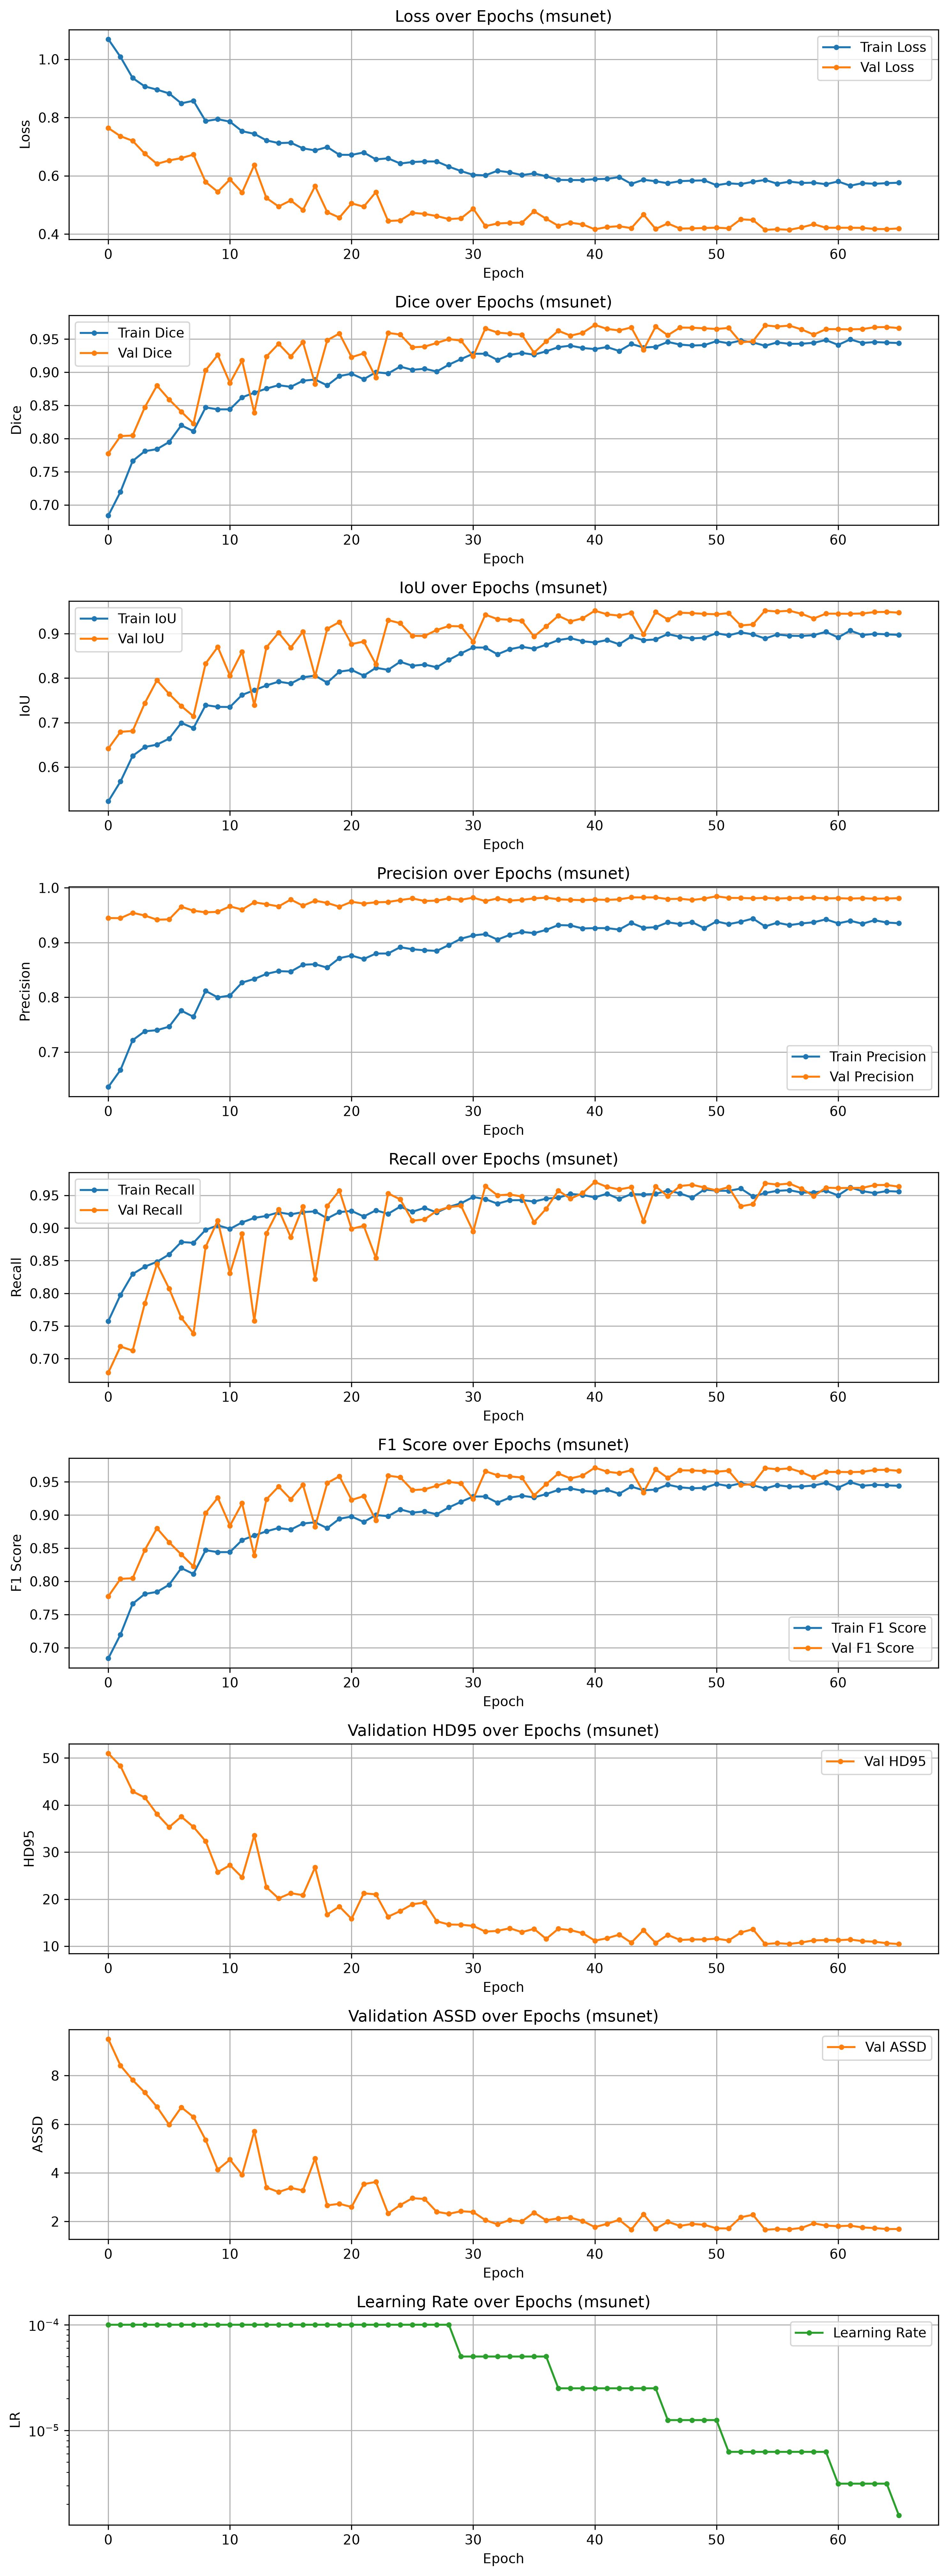

📊 Saved Training Curves: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\figures\training_history_curves.png


In [15]:
def plot_training_history(history, save_dir):
    paired = [
        ('loss', 'Loss'),
        ('dice', 'Dice'),
        ('iou', 'IoU'),
        ('precision', 'Precision'),
        ('recall', 'Recall'),
        ('f1', 'F1 Score'),
    ]
    val_only = [
        ('val_hd95', 'HD95'),
        ('val_assd', 'ASSD'),
    ]
    
    total_plots = len(paired) + len(val_only) + 1
    fig, axes = plt.subplots(total_plots, 1, figsize=(10, total_plots * 3), dpi=300)
    idx = 0
    
    for key, title in paired:
        ax = axes[idx]; idx += 1
        ax.plot(history[f'train_{key}'], label=f'Train {title}', marker='.')
        ax.plot(history[f'val_{key}'], label=f'Val {title}', marker='.')
        ax.set_title(f'{title} over Epochs ({MODEL_NAME})')
        ax.set_xlabel('Epoch'); ax.set_ylabel(title)
        ax.grid(True); ax.legend()
    
    for key, title in val_only:
        ax = axes[idx]; idx += 1
        ax.plot(history[key], label=f'Val {title}', marker='.', color='tab:orange')
        ax.set_title(f'Validation {title} over Epochs ({MODEL_NAME})')
        ax.set_xlabel('Epoch'); ax.set_ylabel(title)
        ax.grid(True); ax.legend()
    
    ax = axes[idx]
    ax.plot(history['learning_rate'], label='Learning Rate', marker='.', color='tab:green')
    ax.set_title(f'Learning Rate over Epochs ({MODEL_NAME})')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR')
    ax.set_yscale('log')
    ax.grid(True); ax.legend()
    
    plt.tight_layout()
    plot_path = os.path.join(save_dir, 'training_history_curves.png')
    fig.savefig(plot_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"📊 Saved Training Curves: {plot_path}")

plot_training_history(history, FIGURES_DIR)


## 14 · Visualise Predictions

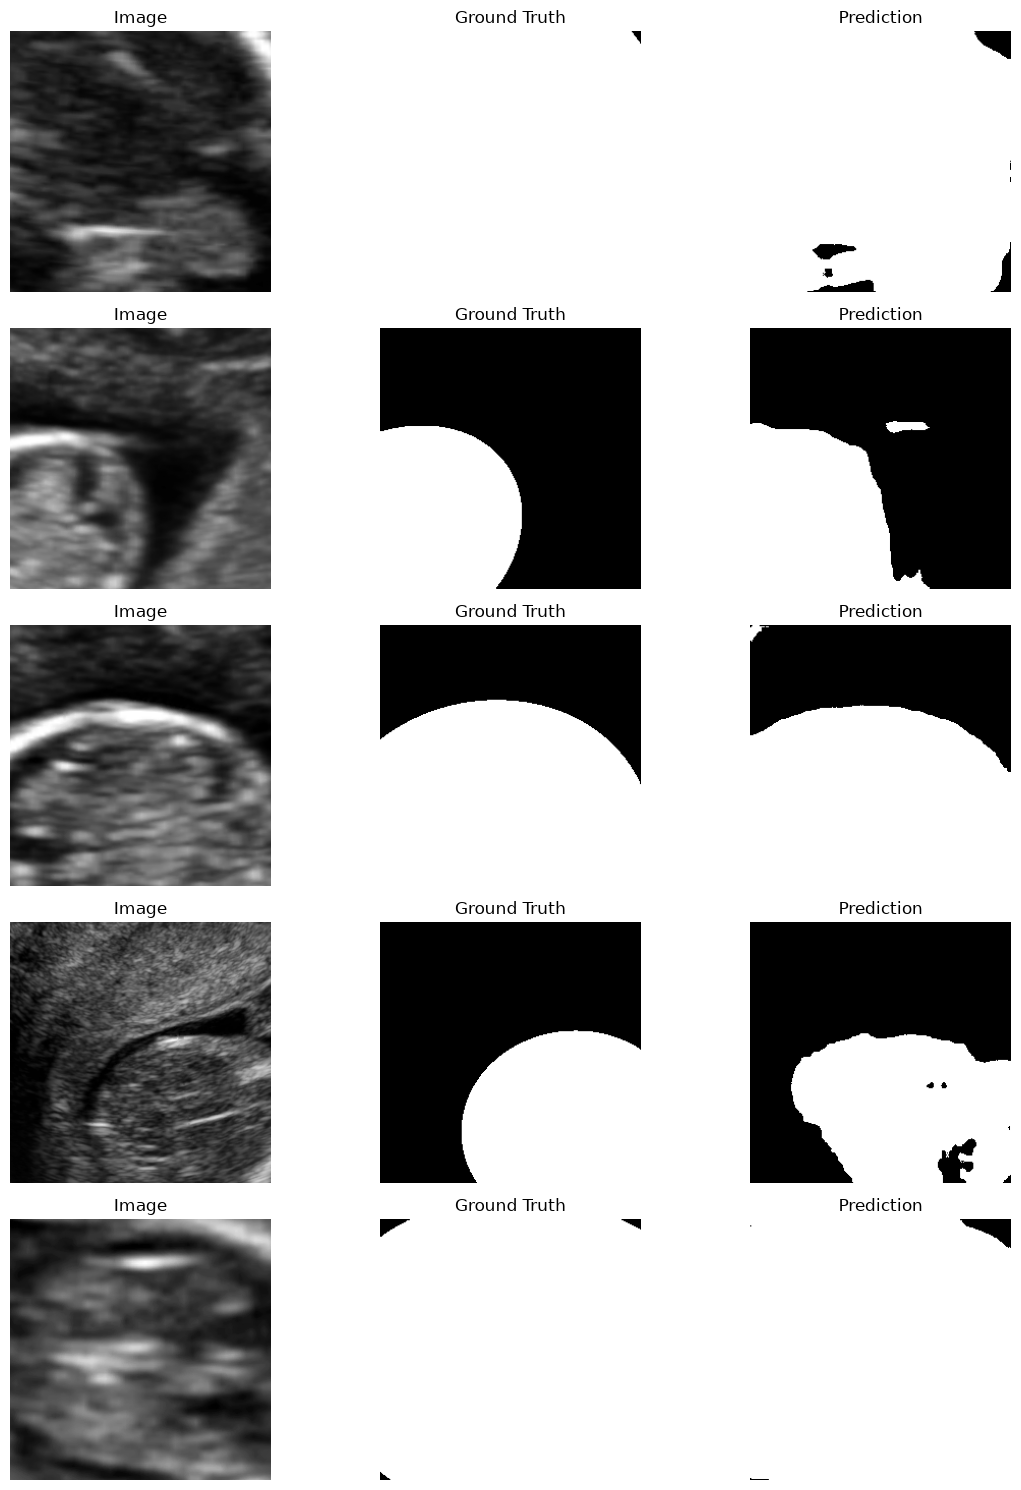

In [16]:
checkpoint = torch.load(best_model_path, map_location=DEVICE)
if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
else:
    model.load_state_dict(checkpoint)
model.eval()

n_samples = 5
fig, axs = plt.subplots(n_samples, 3, figsize=(12, n_samples * 3))

with torch.no_grad():
    for i in range(n_samples):
        img, mask = val_dataset[i]
        img_input = img.unsqueeze(0).to(DEVICE)

        pred = torch.sigmoid(model(img_input))
        pred_mask = (pred[0, 0].cpu().numpy() > 0.5)

        axs[i, 0].imshow(img[0].cpu(), cmap='gray')
        axs[i, 0].set_title("Image")
        axs[i, 0].axis('off')

        axs[i, 1].imshow(mask[0].cpu(), cmap='gray')
        axs[i, 1].set_title("Ground Truth")
        axs[i, 1].axis('off')

        axs[i, 2].imshow(pred_mask, cmap='gray')
        axs[i, 2].set_title("Prediction")
        axs[i, 2].axis('off')

plt.tight_layout()
plt.show()


## 15 · Testing Pipeline & Evaluation

In [17]:
checkpoint = torch.load(best_model_path, map_location=DEVICE)
if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
    best_dice_val = checkpoint.get('best_val_dice', 0.0)
    best_ep = checkpoint.get('epoch', 0) + 1
    print(f"✅ Loaded best model from epoch {best_ep} (Val Dice: {best_dice_val:.4f})")
else:
    model.load_state_dict(checkpoint)
    print("✅ Loaded model weights.")
model.eval()

y_test_dir = os.path.join(DATA_DIR, 'test', 'masks')
test_dataset = FetalHeadDataset(
    x_test_dir, y_test_dir,
    class_gray_values=select_class_gray_values,
    augmentation=get_validation_augmentation(),
    preprocessing=get_preprocessing()
)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)
print(f"Test samples: {len(test_dataset)}")


✅ Loaded best model from epoch 41 (Val Dice: 0.9714)
Test samples: 335


In [18]:
test_metrics = {
    'dice': [], 'iou': [], 'precision': [], 'recall': [], 'f1': [],
    'hd95': [], 'assd': []
}
inference_times = []
per_sample_results = []

model.eval()
with torch.no_grad():
    for idx, (images, masks) in enumerate(tqdm(test_loader, desc="Testing")):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        img_path = test_dataset.image_paths[idx]
        img_name = os.path.basename(img_path)
        
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t_start = time.perf_counter()
        logits = model(images)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t_end = time.perf_counter()
        infer_time = (t_end - t_start) * 1000
        inference_times.append(infer_time)
        
        probs = torch.sigmoid(logits)
        d = to_float(dice_pytorch(probs, masks))
        i = to_float(iou_pytorch(probs, masks))
        p = to_float(precision_pytorch(probs, masks))
        r = to_float(recall_pytorch(probs, masks))
        f = to_float(f1_score_pytorch(probs, masks))
        
        pred_np = (probs > 0.5).cpu().numpy()[0, 0]
        mask_np = (masks > 0.5).cpu().numpy()[0, 0]
        hd95, assd = compute_surface_distances(pred_np, mask_np)
        
        test_metrics['dice'].append(d)
        test_metrics['iou'].append(i)
        test_metrics['precision'].append(p)
        test_metrics['recall'].append(r)
        test_metrics['f1'].append(f)
        if not np.isnan(hd95):
            test_metrics['hd95'].append(hd95)
        if not np.isnan(assd):
            test_metrics['assd'].append(assd)
            
        per_sample_results.append({
            'idx': idx,
            'img_path': img_path,
            'img_name': img_name,
            'dice': d,
            'iou': i,
            'precision': p,
            'recall': r,
            'f1': f,
            'hd95': hd95,
            'assd': assd,
            'image_tensor': images.cpu(),
            'mask_tensor': masks.cpu(),
        })

avg_test = {k: float(np.mean(v)) if v else float('nan') for k, v in test_metrics.items()}
avg_inference_ms = float(np.mean(inference_times))
print("\n✅ Test evaluation complete.")


Testing: 100%|██████████| 335/335 [00:09<00:00, 34.25it/s]


✅ Test evaluation complete.


In [19]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
flops_str = "N/A"
try:
    from ptflops import get_model_complexity_info
    macs, params_str = get_model_complexity_info(
        model, (1, 256, 256), as_strings=True,
        print_per_layer_stat=False, verbose=False
    )
    flops_str = macs
except ImportError:
    try:
        from fvcore.nn import FlopCountAnalysis
        dummy = torch.randn(1, 1, 256, 256).to(DEVICE)
        flop_analysis = FlopCountAnalysis(model, dummy)
        flops_str = f"{flop_analysis.total() / 1e9:.2f} GFLOPs"
    except ImportError:
        flops_str = "N/A (install ptflops or fvcore)"

print(f"\nTrainable Parameters: {num_params:,}")
print(f"FLOPs:                {flops_str}")
print(f"Avg Inference Time:   {avg_inference_ms:.2f} ms")



Trainable Parameters: 7,850,465
FLOPs:                12.37 GMac
Avg Inference Time:   11.94 ms


In [20]:
print(f"\n{'='*60}")
print(f"  TEST RESULTS — {MODEL_NAME}")
print(f"{'='*60}")
print(f"  {'Metric':<25} {'Value':>15}")
print(f"  {'-'*40}")
print(f"  {'Dice':<25} {avg_test['dice']:>15.4f}")
print(f"  {'IoU':<25} {avg_test['iou']:>15.4f}")
print(f"  {'Precision':<25} {avg_test['precision']:>15.4f}")
print(f"  {'Recall':<25} {avg_test['recall']:>15.4f}")
print(f"  {'F1':<25} {avg_test['f1']:>15.4f}")
print(f"  {'HD95':<25} {avg_test['hd95']:>15.4f}")
print(f"  {'ASSD':<25} {avg_test['assd']:>15.4f}")
print(f"  {'-'*40}")
print(f"  {'Parameters':<25} {num_params:>15,}")
print(f"  {'FLOPs':<25} {flops_str:>15}")
print(f"  {'Inference Time (ms)':<25} {avg_inference_ms:>15.2f}")
print(f"{'='*60}")



  TEST RESULTS — msunet
  Metric                              Value
  ----------------------------------------
  Dice                               0.0000
  IoU                                0.0000
  Precision                          0.0000
  Recall                             0.0000
  F1                                 1.0000
  HD95                                  nan
  ASSD                                  nan
  ----------------------------------------
  Parameters                      7,850,465
  FLOPs                          12.37 GMac
  Inference Time (ms)                 11.94


In [21]:
test_csv = pd.DataFrame([{
    'Model': MODEL_NAME,
    'Dice': avg_test['dice'],
    'IoU': avg_test['iou'],
    'Precision': avg_test['precision'],
    'Recall': avg_test['recall'],
    'F1': avg_test['f1'],
    'HD95': avg_test['hd95'],
    'ASSD': avg_test['assd'],
    'Parameters': num_params,
    'FLOPs': flops_str,
    'Inference Time (ms)': round(avg_inference_ms, 2),
}])
test_csv_path = os.path.join(LOGS_DIR, 'test_metrics.csv')
test_csv.to_csv(test_csv_path, index=False)
print(f"📄 Saved Test CSV: {test_csv_path}")


📄 Saved Test CSV: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\logs\test_metrics.csv


---
## 16 · Grad-CAM Explainability Module & Layer Detector

Supports CNN layers, Residual blocks, and Swin Transformer hybrid architectures.  
Automatically identifies the optimal feature extraction layer before or in decoder.

In [22]:
def find_gradcam_target_layer(model):
    """Automatically locate the last meaningful feature extraction layer for Grad-CAM."""
    if hasattr(model, 'decoder') and hasattr(model.decoder, 'blocks'):
        try:
            last_block = model.decoder.blocks[-1]
            convs = [m for m in last_block.modules() if isinstance(m, nn.Conv2d)]
            if convs:
                print(f"🔍 Grad-CAM Layer: Decoder last block Conv2d")
                return convs[-1]
        except Exception:
            pass
            
    conv_modules = []
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            conv_modules.append((name, module))
            
    if conv_modules:
        swin_pre_convs = [m for name, m in conv_modules if 'bridge' in name.lower() or 'pre_swin' in name.lower()]
        if swin_pre_convs:
            print(f"🔍 Grad-CAM Layer: Pre-Swin Transformer Conv layer")
            return swin_pre_convs[-1]
            
        last_name, last_conv = conv_modules[-1]
        print(f"🔍 Grad-CAM Layer: '{last_name}' (last Conv2d layer)")
        return last_conv
        
    raise ValueError("No Conv2d layer found in model for Grad-CAM!")

def compute_gradcam(model, input_tensor, target_layer):
    """Compute normalized Grad-CAM heatmap (2D numpy array [0, 1])."""
    activations = []
    gradients = []
    
    def forward_hook(module, input, output):
        activations.append(output.detach())
        
    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0].detach())
        
    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_full_backward_hook(backward_hook)
    
    model.zero_grad()
    x = input_tensor.clone().detach().requires_grad_(True)
    logits = model(x)
    probs = torch.sigmoid(logits)
    
    target_score = probs.sum()
    target_score.backward()
    
    fh.remove()
    bh.remove()
    
    if not activations or not gradients:
        return np.zeros((input_tensor.shape[2], input_tensor.shape[3]))
        
    act = activations[0]
    grad = gradients[0]
    
    weights = grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * act).sum(dim=1))[0].cpu().numpy()
    
    if cam.max() > cam.min():
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    else:
        cam = np.zeros_like(cam)
        
    cam_resized = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))
    return cam_resized


## 17 · Side-by-Side Explainability Visualizer

Generates the 6-panel publication layout:  
`Original` | `Ground Truth` | `Prediction`  
`Grad-CAM` | `Overlay (0.4×Img + 0.6×Cam)` | `Prediction Overlay`

In [23]:
def create_explainability_figure(img_np, gt_mask, pred_mask, cam_map, title_prefix=""):
    """Construct high-res 6-panel side-by-side comparison figure."""
    if img_np.ndim == 2:
        orig_rgb = cv2.cvtColor((img_np * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
    else:
        orig_rgb = (img_np * 255).astype(np.uint8)
        
    gt_vis = (gt_mask * 255).astype(np.uint8)
    gt_rgb = cv2.cvtColor(gt_vis, cv2.COLOR_GRAY2RGB)
    
    pred_vis = (pred_mask * 255).astype(np.uint8)
    pred_rgb = cv2.cvtColor(pred_vis, cv2.COLOR_GRAY2RGB)
    
    cam_u8 = (cam_map * 255).astype(np.uint8)
    cam_jet = cv2.applyColorMap(cam_u8, cv2.COLORMAP_JET)
    cam_jet_rgb = cv2.cvtColor(cam_jet, cv2.COLOR_BGR2RGB)
    
    overlay = np.uint8(np.clip(0.4 * (orig_rgb / 255.0) + 0.6 * (cam_jet_rgb / 255.0), 0, 1) * 255)
    
    pred_overlay = orig_rgb.copy()
    contours, _ = cv2.findContours(pred_vis, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        cv2.drawContours(pred_overlay, contours, -1, (0, 255, 0), 2)
        
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), dpi=300)
    
    panels = [
        (axes[0, 0], orig_rgb, "Original Ultrasound"),
        (axes[0, 1], gt_rgb, "Ground Truth"),
        (axes[0, 2], pred_rgb, "Prediction"),
        (axes[1, 0], cam_jet_rgb, "Grad-CAM Heatmap"),
        (axes[1, 1], overlay, "Grad-CAM Overlay (0.4/0.6)"),
        (axes[1, 2], pred_overlay, "Prediction Overlay (Contour)"),
    ]
    
    for ax, image, name in panels:
        ax.imshow(image)
        ax.set_title(name, fontsize=12, fontweight='bold')
        ax.axis('off')
        
    if title_prefix:
        fig.suptitle(title_prefix, fontsize=14, fontweight='bold')
        
    plt.tight_layout()
    return fig, cam_jet_rgb, overlay


## 18 · Dice Ranking, Grad-CAM Generation & Quantitative Report (`<MODEL_NAME>/logs/gradcam_report.csv`)

In [24]:
gradcam_layer = find_gradcam_target_layer(model)

sorted_samples = sorted(per_sample_results, key=lambda x: x['dice'], reverse=True)
top10_best = sorted_samples[:10]
top10_worst = sorted_samples[-10:]

random.seed(42)
random_20 = random.sample(per_sample_results, min(20, len(per_sample_results)))

print(f"Top Best Dice:  {top10_best[0]['dice']:.4f}")
print(f"Worst Dice:     {top10_worst[0]['dice']:.4f}")


🔍 Grad-CAM Layer: 'outc' (last Conv2d layer)
Top Best Dice:  0.0000
Worst Dice:     0.0000


In [25]:
report_rows = []
processed_indices = set()

target_groups = [
    ('best', top10_best),
    ('worst', top10_worst),
    ('random', random_20)
]

for group_name, group_samples in target_groups:
    for sample in group_samples:
        idx = sample['idx']
        img_name = sample['img_name']
        img_tensor = sample['image_tensor'].to(DEVICE)
        mask_tensor = sample['mask_tensor'].to(DEVICE)
        
        cam = compute_gradcam(model, img_tensor, gradcam_layer)
        
        img_np = img_tensor[0, 0].cpu().numpy()
        gt_np = (mask_tensor[0, 0].cpu().numpy() > 0.5).astype(np.uint8)
        
        with torch.no_grad():
            prob = torch.sigmoid(model(img_tensor))[0, 0].cpu().numpy()
            pred_np = (prob > 0.5).astype(np.uint8)
            
        title = f"Model: {MODEL_NAME} | Image: {img_name} | Dice: {sample['dice']:.4f} | Group: {group_name.upper()}"
        fig, cam_jet, overlay = create_explainability_figure(img_np, gt_np, pred_np, cam, title_prefix=title)
        
        save_path = os.path.join(GRADCAM_DIR, f"{group_name}_{img_name}")
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close(fig)
        
        gt_bool = gt_np.astype(bool)
        mean_inside = float(cam[gt_bool].mean()) if gt_bool.any() else 0.0
        mean_outside = float(cam[~gt_bool].mean()) if (~gt_bool).any() else 0.0
        coverage = float((cam[gt_bool] > 0.5).sum() / (gt_bool.sum() + 1e-8) * 100) if gt_bool.any() else 0.0
        
        if idx not in processed_indices:
            processed_indices.add(idx)
            report_rows.append({
                'Model': MODEL_NAME,
                'Image Name': img_name,
                'Group': group_name,
                'Dice Score': sample['dice'],
                'IoU': sample['iou'],
                'Precision': sample['precision'],
                'Recall': sample['recall'],
                'Mean Heatmap Intensity inside Ground Truth': round(mean_inside, 4),
                'Mean Heatmap Intensity outside Ground Truth': round(mean_outside, 4),
                'Heatmap Coverage (%)': round(coverage, 2),
            })

report_df = pd.DataFrame(report_rows)
report_path = os.path.join(LOGS_DIR, 'gradcam_report.csv')
report_df.to_csv(report_path, index=False)
print(f"📄 Saved Grad-CAM Report: {report_path}")


📄 Saved Grad-CAM Report: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\logs\gradcam_report.csv


## 19 · Feature Map & Attention Map Visualizations (`<MODEL_NAME>/feature_maps/`, `<MODEL_NAME>/attention_maps/`)

In [26]:
def visualize_feature_maps(model, sample_tensor, save_dir):
    """Extract and visualize feature maps from Encoder, AMSFF, Bridge, and Decoder modules."""
    activations = {}
    hooks = []
    
    for name, module in model.named_modules():
        if 'encoder' in name.lower() and isinstance(module, nn.Conv2d):
            activations['Encoder'] = (name, module)
        elif 'amsff' in name.lower() and isinstance(module, nn.Conv2d):
            activations['AMSFF'] = (name, module)
        elif ('swin' in name.lower() or 'bridge' in name.lower()) and isinstance(module, nn.Conv2d):
            activations['Bridge'] = (name, module)
        elif 'decoder' in name.lower() and isinstance(module, nn.Conv2d):
            activations['Decoder'] = (name, module)
            
    act_maps = {}
    for comp_name, (mod_name, module) in list(activations.items()):
        def hook_fn(m, i, o, key=comp_name):
            act_maps[key] = o.detach()
        hooks.append(module.register_forward_hook(hook_fn))
        
    with torch.no_grad():
        _ = model(sample_tensor.to(DEVICE))
        
    for h in hooks:
        h.remove()
        
    for comp_name, feat_map in act_maps.items():
        feat_np = feat_map[0].cpu().numpy()
        n_channels = min(16, feat_np.shape[0])
        
        fig, axes = plt.subplots(4, 4, figsize=(10, 10), dpi=300)
        fig.suptitle(f"Feature Maps — {comp_name} ({MODEL_NAME})", fontsize=14, fontweight='bold')
        
        for idx in range(16):
            ax = axes[idx // 4, idx % 4]
            if idx < n_channels:
                ch_map = feat_np[idx]
                ch_norm = (ch_map - ch_map.min()) / (ch_map.max() - ch_map.min() + 1e-8)
                ax.imshow(ch_norm, cmap='viridis')
                ax.set_title(f"Ch {idx+1}", fontsize=8)
            ax.axis('off')
            
        plt.tight_layout()
        save_p = os.path.join(save_dir, f"feature_map_{comp_name.lower()}.png")
        fig.savefig(save_p, dpi=300, bbox_inches='tight')
        plt.close(fig)
        print(f"🖼️  Saved Feature Maps: {save_p}")

sample_tensor = per_sample_results[0]['image_tensor']
visualize_feature_maps(model, sample_tensor, FEATUREMAP_DIR)


In [27]:
def visualize_attention_maps(model, sample_tensor, img_np, save_dir):
    """Safely detect and visualize attention maps if attention modules exist."""
    attn_modules = []
    for name, module in model.named_modules():
        mod_type = type(module).__name__.lower()
        if any(k in mod_type for k in ['attention', 'attn', 'spatialattn', 'channelattn']):
            attn_modules.append((name, module))
            
    if not attn_modules:
        print("ℹ️  No specific attention modules detected in target model architecture.")
        return
        
    print(f"🔍 Found {len(attn_modules)} attention module(s).")
    act_dict = {}
    hooks = []
    for name, mod in attn_modules[:4]:
        def hook_fn(m, i, o, key=name):
            if isinstance(o, (tuple, list)):
                act_dict[key] = o[0].detach()
            else:
                act_dict[key] = o.detach()
        hooks.append(mod.register_forward_hook(hook_fn))
        
    with torch.no_grad():
        _ = model(sample_tensor.to(DEVICE))
    for h in hooks:
        h.remove()
        
    for name, attn_map in act_dict.items():
        am = attn_map[0].cpu().numpy()
        if am.ndim == 3:
            am = am.mean(axis=0)
        am_norm = (am - am.min()) / (am.max() - am.min() + 1e-8)
        am_upsampled = cv2.resize(am_norm, (256, 256))
        
        orig_rgb = cv2.cvtColor((img_np * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
        attn_jet = cv2.cvtColor(cv2.applyColorMap((am_upsampled * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        overlay = np.uint8(np.clip(0.4*(orig_rgb/255) + 0.6*(attn_jet/255), 0, 1) * 255)
        
        fig, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=300)
        ax.imshow(overlay)
        ax.set_title(f"Attention Overlay — {name} ({MODEL_NAME})", fontsize=12, fontweight='bold')
        ax.axis('off')
        clean_name = name.replace('.', '_')
        save_p = os.path.join(save_dir, f"attention_{clean_name}.png")
        fig.savefig(save_p, dpi=300, bbox_inches='tight')
        plt.close(fig)
        print(f"🖼️  Saved Attention Map: {save_p}")

sample_img_np = per_sample_results[0]['image_tensor'][0, 0].numpy()
visualize_attention_maps(model, sample_tensor, sample_img_np, ATTENTION_DIR)


ℹ️  No specific attention modules detected in target model architecture.


## 20 · Publication-Ready Figures in `<MODEL_NAME>/figures/` (300 DPI)

Exports:  
- `Figure1_Random_Qualitative_Results.png`  
- `Figure2_Best_Predictions.png`  
- `Figure3_Worst_Predictions.png`  
- `Figure4_GradCAM_Explanation.png`  
- `Figure5_Attention_Maps.png`

In [28]:
def create_publication_grid(samples, title, save_filename):
    """Generates a publication-ready 4x3 grid figure at 300 DPI."""
    n_rows = min(4, len(samples))
    fig, axes = plt.subplots(n_rows, 3, figsize=(12, 3 * n_rows), dpi=300)
    fig.suptitle(f"{title} — {MODEL_NAME}", fontsize=16, fontweight='bold')
    
    for idx in range(n_rows):
        s = samples[idx]
        img_np = s['image_tensor'][0, 0].numpy()
        gt_np = s['mask_tensor'][0, 0].numpy()
        
        with torch.no_grad():
            prob = torch.sigmoid(model(s['image_tensor'].to(DEVICE)))[0, 0].cpu().numpy()
            pred_np = (prob > 0.5).astype(np.uint8)
            
        orig_rgb = cv2.cvtColor((img_np * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours((pred_np * 255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            cv2.drawContours(orig_rgb, contours, -1, (0, 255, 0), 2)
            
        row_axes = axes[idx] if n_rows > 1 else axes
        row_axes[0].imshow(img_np, cmap='gray')
        row_axes[0].set_title(f"Image: {s['img_name']}", fontsize=10)
        row_axes[0].axis('off')
        
        row_axes[1].imshow(gt_np, cmap='gray')
        row_axes[1].set_title(f"Ground Truth", fontsize=10)
        row_axes[1].axis('off')
        
        row_axes[2].imshow(orig_rgb)
        row_axes[2].set_title(f"Pred Overlay (Dice: {s['dice']:.4f})", fontsize=10)
        row_axes[2].axis('off')
        
    plt.tight_layout()
    save_path = os.path.join(FIGURES_DIR, save_filename)
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close(fig)
    print(f"📊 Saved Publication Figure: {save_path}")

# Figure 1: Random qualitative results
create_publication_grid(random_20, "Figure 1: Random Qualitative Results", "Figure1_Random_Qualitative_Results.png")

# Figure 2: Best predictions
create_publication_grid(top10_best, "Figure 2: Best Predictions (Top Dice)", "Figure2_Best_Predictions.png")

# Figure 3: Worst predictions
create_publication_grid(top10_worst, "Figure 3: Worst Predictions (Lowest Dice)", "Figure3_Worst_Predictions.png")

# Figure 4: Grad-CAM Explanation
s_best = top10_best[0]
cam_best = compute_gradcam(model, s_best['image_tensor'].to(DEVICE), gradcam_layer)
fig4, _, _ = create_explainability_figure(
    s_best['image_tensor'][0, 0].numpy(),
    (s_best['mask_tensor'][0, 0].numpy() > 0.5).astype(np.uint8),
    (torch.sigmoid(model(s_best['image_tensor'].to(DEVICE)))[0, 0].detach().cpu().numpy() > 0.5).astype(np.uint8),
    cam_best,
    title_prefix=f"Figure 4: Grad-CAM Explanation — {s_best['img_name']} (Dice: {s_best['dice']:.4f})"
)
fig4_path = os.path.join(FIGURES_DIR, "Figure4_GradCAM_Explanation.png")
fig4.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.close(fig4)
print(f"📊 Saved Publication Figure: {fig4_path}")

# Figure 5: Attention Maps
fig5_path = os.path.join(FIGURES_DIR, "Figure5_Attention_Maps.png")
att_files = glob(os.path.join(ATTENTION_DIR, "*.png"))
if att_files:
    att_img = cv2.imread(att_files[0])
    cv2.imwrite(fig5_path, att_img)
else:
    fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
    ax.text(0.5, 0.5, f"No explicit Attention modules\nin model architecture '{MODEL_NAME}'", ha='center', va='center', fontsize=14)
    ax.axis('off')
    fig.savefig(fig5_path, dpi=300, bbox_inches='tight')
    plt.close(fig)
print(f"📊 Saved Publication Figure: {fig5_path}")

print(f"\n🎉 Experiment complete for '{MODEL_NAME}'!")
print(f"📁 All artifacts cleanly stored inside dedicated folder:")
print(f"   └── {MODEL_DIR}")


📊 Saved Publication Figure: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\figures\Figure1_Random_Qualitative_Results.png
📊 Saved Publication Figure: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\figures\Figure2_Best_Predictions.png
📊 Saved Publication Figure: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\figures\Figure3_Worst_Predictions.png
📊 Saved Publication Figure: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\figures\Figure4_GradCAM_Explanation.png
📊 Saved Publication Figure: C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet\figures\Figure5_Attention_Maps.png

🎉 Experiment complete for 'msunet'!
📁 All artifacts cleanly stored inside dedicated folder:
   └── C:\Users\shyle\OneDrive\Documents\Projects\Fetus\Experiments\msunet
